# **Nama: Andika Dinata**
# **NIM: 123140096**

In [32]:
# Memuat library yang dibutuhkan dalam pemrosesan data dan pembuatan
# model dengan menggunakan KNN, Decision Tree, dan Naive Bayes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## **1. Data Loading and Preparation**

### **1.1 Memuat dataset**

In [33]:
# Memuat dataset
dataset = load_wine()

# Mengecek tipe dari dataset
print(type(dataset))

# Mengecek informasi yang terdapat dalam dataset dictionary keys
print(dataset.keys())

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])


Memuat dataset dan memeriksa informasi yang tersedia di dataset dictionary keys

In [34]:
# Mencetak / menampilkan deskripsi dari dataset
print(dataset['DESCR'])

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

Melihat fitur/kolom/dimensi yang ada di dalam dataset

### **1.2 Membuat DataFrame dan menambahkan label**

In [35]:
# Memuat kumpulan data feature ke dalam pandas DataFrame
dataset_df = pd.DataFrame(data=dataset['data'], columns=dataset['feature_names'])
dataset_df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [36]:
# Menambahkan informasi varible target pada setiap baris data dalam DataFrame
dataset_df['class'] = dataset['target']
dataset_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Memasukkan dataset ke Dataframe agar mudah dianalisa

### **1.3 Memeriksa nilai yang hilang (missing values)**

In [37]:
# Mengecek terhadap nilai yang kosong (missing values)
print(np.sum(np.isnan(dataset_df)))

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
class                           0
dtype: int64


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


Melihat nilai yang kosong dari setiap kolom dataset

### **1.4 Memisahkan fitur (X) dan target (y)**

In [38]:
# y merupakan variable dependent, target variable (yang akan diestimasi oleh model kita)
y = dataset_df['class']

# X merupakan features yang akan diberikan kepada model. iloc digunakan untuk
# melakukan slice pada DataFrame.
X = dataset_df.iloc[:, :-1]

# Menampilkan ukuran dari setiap variabel X dan y
print(f"Data X = {X.shape}")
print(f"Data y = {y.shape}")

Data X = (178, 13)
Data y = (178,)


Memeriksa apakah ukuran dari variable X dan Y itu sama

### **1.5 Normalisasi data**

In [39]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X.values.reshape(-1, X.shape[1]))
X = pd.DataFrame(X)
print(f"Contoh data X setelah normalisasi \n{X.head()}\n")

Contoh data X setelah normalisasi 
         0         1         2         3         4         5         6   \
0  0.842105  0.191700  0.572193  0.257732  0.619565  0.627586  0.573840   
1  0.571053  0.205534  0.417112  0.030928  0.326087  0.575862  0.510549   
2  0.560526  0.320158  0.700535  0.412371  0.336957  0.627586  0.611814   
3  0.878947  0.239130  0.609626  0.319588  0.467391  0.989655  0.664557   
4  0.581579  0.365613  0.807487  0.536082  0.521739  0.627586  0.495781   

         7         8         9         10        11        12  
0  0.283019  0.593060  0.372014  0.455285  0.970696  0.561341  
1  0.245283  0.274448  0.264505  0.463415  0.780220  0.550642  
2  0.320755  0.757098  0.375427  0.447154  0.695971  0.646933  
3  0.207547  0.558360  0.556314  0.308943  0.798535  0.857347  
4  0.490566  0.444795  0.259386  0.455285  0.608059  0.325963  



Melakukan normalisasi data menggunakan MinMaxScaler sehingga nilai dari setiap fitur/kolom akan berada di rentang 0 sampai 1. Tujuannya agar tidak ada fitur yang dominan karena angka nya besar, jika tidak dilakukan normalisasi.

### **1.6 Membagi data latih dan data uji**

In [40]:
# Proses pembagian kumpulan data ke dalam data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print(f"Shapes")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

Shapes
X_train: (124, 13), X_test: (54, 13)
y_train: (124,), y_test: (54,)


Membagi dataset untuk training dan testing dengan rasio 7 : 3

## **2. Model Definition (KNN, Decision Tree, Naive Bayes)**

In [41]:
# Dokumentasi dari penggunaan KNN
# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
num_neighbors = 10
modelKNN = KNeighborsClassifier(n_neighbors=num_neighbors)

# Dokumentasi dari penggunaan Decision Tree
# https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
type_splitter = 'best'
modelDT = DecisionTreeClassifier(splitter=type_splitter, random_state=0)

# Dokumentasi dari penggunaan Gaussian Naive Bayes
# https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
modelNB = GaussianNB()

Ketiga model memiliki cara kerja yang berbeda.

KNN menentukan kelas data baru berdasarkan 10 tetangga terdekat pada data latih. Jarak yang digunakan adalah Euclidean dan semua tetangga memiliki bobot yang sama. Pemilihan nilai K juga memengaruhi model. K yang kecil cenderung lebih sensitif terhadap noise sehingga bisa menyebabkan overfitting, sedangkan K yang besar membuat hasil lebih halus tetapi bisa menyebabkan underfitting. KNN juga disebut lazy learner karena tidak membuat model secara langsung saat proses training.

Decision Tree bekerja dengan membuat aturan if-else secara bertahap untuk membagi data. Pada setiap percabangan, splitter='best' digunakan untuk mencari pembagian yang paling baik berdasarkan fitur dan nilai tertentu. Karena tidak ada batas kedalaman, pohon bisa terus berkembang dan berisiko mengalami overfitting.

Model ini menggunakan teorema Bayes untuk menentukan kelas data. Perhitungannya didasarkan pada dua asumsi, yaitu setiap fitur dianggap saling independen dan nilai setiap fitur mengikuti distribusi Gaussian pada masing-masing kelas. Dalam pengaturan ini, tidak ada hyperparameter utama yang perlu diatur.

---
## 3. Training Process

In [42]:
# Proses pelatihan untuk masing-masing model
modelKNN.fit(X_train, y_train)
modelDT.fit(X_train, y_train)
modelNB.fit(X_train, y_train)

GaussianNB()

KNN

fit() pada dasarnya hanya menyimpan data latih. Perhitungan jarak dan penentuan kelas baru dilakukan saat predict().


Decision Tree

fit() membangun pohon dengan mencari pemisahan yang paling baik pada setiap simpul, lalu mengulang proses tersebut secara bertahap.


Gaussian NB

fit() menghitung prior setiap kelas serta rata-rata dan varians setiap fitur pada masing-masing kelas. Karena hanya melakukan perhitungan statistik, prosesnya relatif cepat.

## **4. Testing Process**

### **4.1 Pengujian KNN**

In [43]:
# Proses prediksi dari testing data menggunakan modelKNN
y_predKNN = modelKNN.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predKNN))
print("\nClassification Report:")
print(classification_report(y_test, y_predKNN))

Confusion Matrix:
[[19  0  0]
 [ 1 21  0]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.95      0.98        22
           2       1.00      1.00      1.00        13

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



Kelas 2 hasilnya sangat akurat.
Kelas 0 hasilnya yang paling jelek.

### 4.2 Pengujian Decision Tree

In [44]:
# Proses prediksi dari testing data menggunakan modelDT
y_predDT = modelDT.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predDT))
print("\nClassification Report:")
print(classification_report(y_test, y_predDT))

Confusion Matrix:
[[17  2  0]
 [ 0 21  1]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        19
           1       0.91      0.95      0.93        22
           2       0.93      1.00      0.96        13

    accuracy                           0.94        54
   macro avg       0.95      0.95      0.95        54
weighted avg       0.95      0.94      0.94        54



Decision Tree lebih rendah performanya dibandingkan KNN.

### 4.3 Pengujian Naive Bayes

In [45]:
# Proses prediksi dari testing data menggunakan modelNB
y_predNB = modelNB.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predNB))
print("\nClassification Report:")
print(classification_report(y_test, y_predNB))

Confusion Matrix:
[[19  0  0]
 [ 2 19  1]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        19
           1       1.00      0.86      0.93        22
           2       0.93      1.00      0.96        13

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.95        54
weighted avg       0.95      0.94      0.94        54



Naive Bayes hasilnya second best dari KNN. Lebih baik daripada Decision Tree.

## **5. Result Analysis**



### **5.1 Analisis hasil KNN**

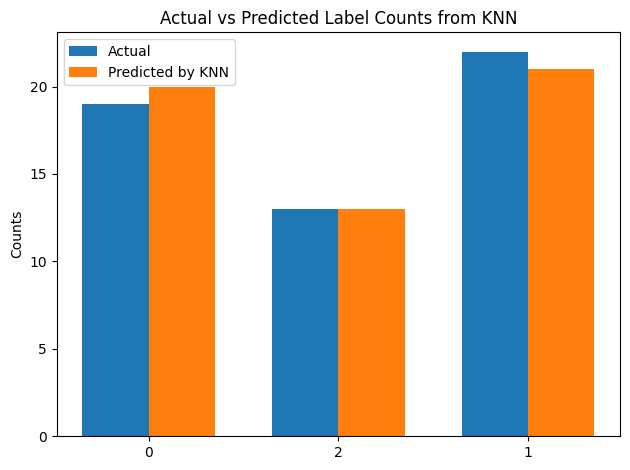

In [46]:
# Analisis untuk hasil yang diberikan dari modelKNN
labels = y_test.unique()
x = np.arange(len(labels))  # pengaturan lokasi dari label
width = 0.35  # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predKNN
y_test_counts = y_test.value_counts().sort_index()
y_predKNN_counts = pd.Series(y_predKNN).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predKNN_counts = y_predKNN_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predKNN_counts, width, label='Predicted by KNN')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from KNN')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.show()

Hanya 1 kelas yang hasilnya akurat atau sama dengan data asli. Tapi sisa kelasnya tidak berbeda terlalu jauh.

### 5.2 Analisis hasil Decision Tree

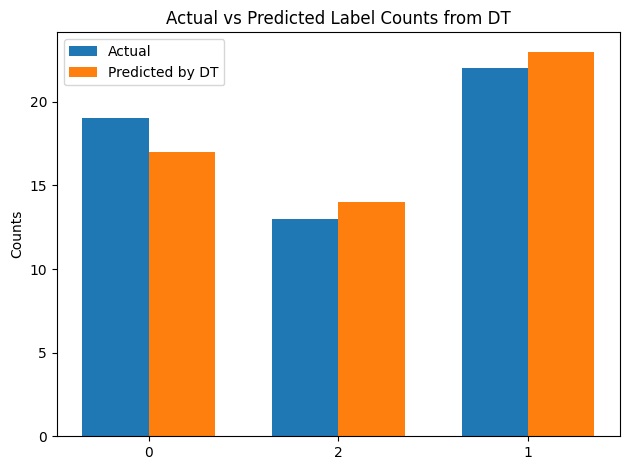

In [47]:
# Analisis untuk hasil yang diberikan dari modelDT
labels = y_test.unique()
x = np.arange(len(labels))  # pengaturan lokasi dari label
width = 0.35  # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predDT
y_test_counts = y_test.value_counts().sort_index()
y_predDT_counts = pd.Series(y_predDT).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predDT_counts = y_predDT_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predDT_counts, width, label='Predicted by DT')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from DT')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.show()

Tidak ada kelas yang hasilnya akurat atau sama dengan data asli. Tapi selisih dari data aslinya tidak terlalu jauh.

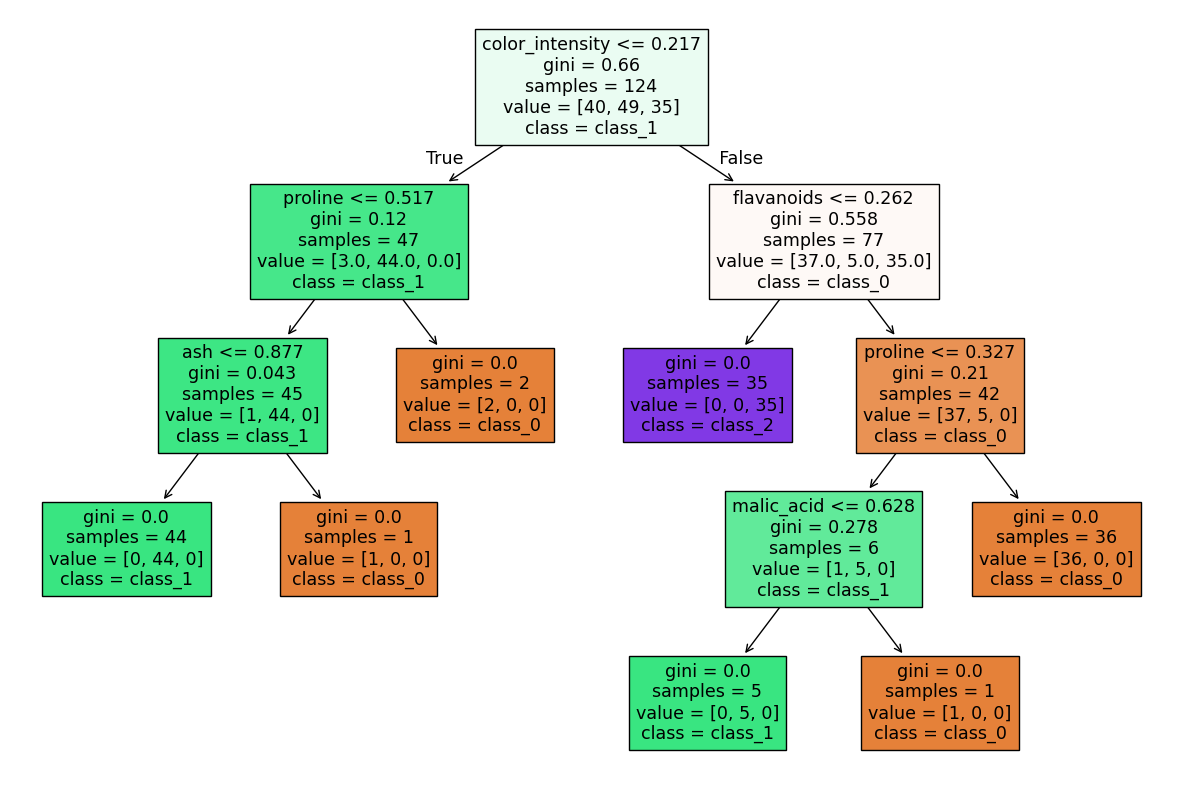

In [48]:
# Visualisasi dari pohon keputusan yang berdasarkan pada modelDT
plt.figure(figsize=(15, 10))
tree.plot_tree(modelDT, feature_names=dataset['feature_names'], class_names=dataset['target_names'], filled=True)
plt.show()

Decision Tree lebih mudah untuk ditrack bagaimana sebuah hasil prediksi bisa muncul. Hanya saja pada kasus ini hasilnya kurang baik, mungkin karena kurang cocok dengan dataset ini.

Kalau datasetnya binary harusnya lebih bagus.

### 5.3 Analisis hasil Naive Bayes

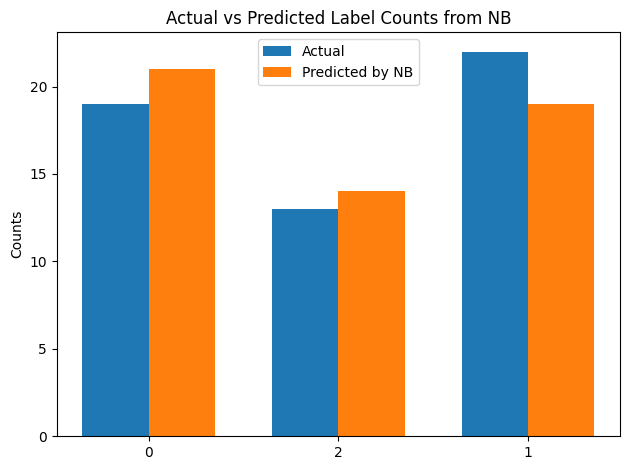

In [49]:
# Analisis untuk hasil yang diberikan dari modelNB
labels = y_test.unique()
x = np.arange(len(labels))  # pengaturan lokasi dari label
width = 0.35  # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predNB
y_test_counts = y_test.value_counts().sort_index()
y_predNB_counts = pd.Series(y_predNB).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predNB_counts = y_predNB_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predNB_counts, width, label='Predicted by NB')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from NB')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.show()

Sama seperti decision tree, tidak ada kelas yang hasilnya akurat atau sama dengan data asli. Selisihnya tidak terlalu jauh, mungkin bar kelas 1 di diagram ini lebih terlihat lebih jauh dibandingkan bar-bar pada diagram sebelumnya

### **5.4 Parameter yang dipelajari Naive Bayes**

In [50]:
# Menampilkan beberapa parameter yang dihasilkan dari pelatihan modelNB
print("Varians dari setiap fitur pada setiap kelas:")
print(modelNB.var_)

print("\nMean dari setiap fitur pada setiap kelas:")
print(modelNB.theta_)

Varians dari setiap fitur pada setiap kelas:
[[0.01461157 0.01966651 0.01574387 0.01768186 0.01126529 0.01611712
  0.00771155 0.01642377 0.01771067 0.01214072 0.00843244 0.01764333
  0.02298298]
 [0.02282168 0.03404014 0.02788854 0.0336155  0.04088866 0.02639526
  0.01438521 0.04647257 0.04260036 0.00429426 0.02976924 0.0295189
  0.01300407]
 [0.01619552 0.05142655 0.00980516 0.01402045 0.0144001  0.01132593
  0.00353279 0.0543373  0.01242834 0.03782161 0.00816273 0.00899752
  0.0060916 ]]

Mean dari setiap fitur pada setiap kelas:
[[0.70842105 0.25568182 0.57459893 0.3132732  0.37527174 0.63887931
  0.5596519  0.29481132 0.47996845 0.3615401  0.47947154 0.6981685
  0.59802068]
 [0.33066595 0.23860611 0.47113391 0.50568062 0.28881988 0.4190007
  0.34762766 0.43819792 0.39992275 0.14163823 0.47064875 0.5610376
  0.18042738]
 [0.54834586 0.52461886 0.5842628  0.5640648  0.32546584 0.24502463
  0.09168174 0.61563342 0.23551149 0.51301804 0.16376307 0.1451596
  0.24852252]]


Gaussian Naive Bayes mengasumsikan setiap fitur mengikuti distribusi normal pada tiap kelas. Saat training, model menghitung rata-rata, varians, dan prior untuk menentukan probabilitas setiap kelas. Fitur seperti flavanoids, od280/od315, hue, proline, dan color_intensity cukup membantu membedakan kelas karena nilai rata-ratanya berbeda jauh. Kelas 2 paling mudah dikenali, sedangkan kelas 1 lebih beragam sehingga lebih banyak tumpang tindih dengan kelas lain. Meski asumsi antarfitur tidak sepenuhnya terpenuhi, model tetap akurat selama kelas yang benar memiliki probabilitas terbesar.

### **5.5 Perbandingan ketiga model**

Ketiga model menghasilkan akurasi tinggi, dengan KNN sebesar 98%, sedangkan Decision Tree dan Naive Bayes sama-sama 94%. Kelas 2 paling mudah dikenali oleh semua model, sedangkan kesalahan lebih banyak terjadi pada kelas 0 dan 1 yang lebih mirip.